### Code for making a CHM map for Edinburgh.

These first few lines are used to find properties of an example DSM file

In [1]:
import numpy as np
from sys import exit
import rasterio

filename = '/home/s2955015/scratch/LiDAR/DSM/NT17NE_50CM_DSM_PHASE5 (1).tif'

datafile = rasterio.open(filename)

data = datafile.read(1)

# Filters out negative values
data[data < 0.0] = np.nan

res = datafile.res
nX = datafile.width
nY = datafile.height

print('x resolution', round(res[0], 2), 'm. y resolution', round(res[1], 2), 'm')
print('The raster has', nX, 'by', nY, 'pixels')

x resolution 0.5 m. y resolution 0.5 m
The raster has 10000 by 10000 pixels


In [2]:
useableData = data[np.isnan(data) == False]

meanElev = np.mean(useableData)
print('Mean elevation is', round(meanElev, 2), 'm')

stdevElev = np.std(useableData)
print('The standard deviation of elevation is', round(stdevElev, 2), 'm')

Mean elevation is 28.06 m
The standard deviation of elevation is 25.68 m


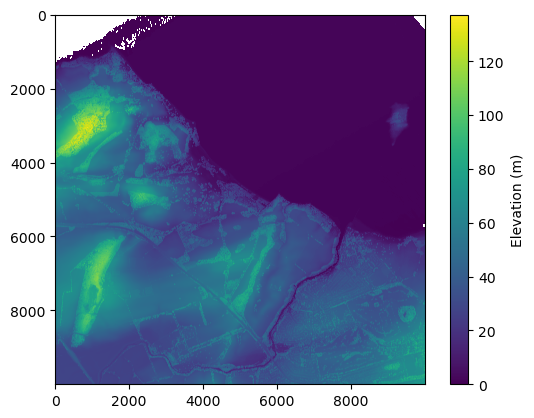

In [3]:
import matplotlib.pyplot as plt

plt.imshow(data)
plt.colorbar(label='Elevation (m)')
plt.show()

Import one DSM and DTM

In [4]:
def heightAboveGround(dtmName, dsmName):
    
    dtmFile=rasterio.open(dtmName)
    dtm=dtmFile.read(1)
    dsmFile=rasterio.open(dsmName)
    dsm=dsm.File.read(1)
    
    dtm[dtm<0.0] = np.nan
    dsm[dsm<0.0] = np.nan
    
    hData=dsm-dtm
    
    return(hData,dtmFile)

dsmName = '/home/s2955015/scratch/LiDAR/DSM/NT17NE_50CM_DSM_PHASE5 (1).tif'
dtmName = '/home/s2955015/scratch/LiDAR/DTM/NT17NE_50CM_DTM_PHASE5.tif'

Import the rest of the DSM and DTM files from their respective directories. 

In [16]:
from glob import glob

dtmDir='/home/s2955015/scratch/LiDAR/DTM'
dsmDir='/home/s2955015/scratch/LiDAR/DSM'

dtmList=sorted(glob(dtmDir+'/*.tif'))
dsmList=sorted(glob(dsmDir+'/*.tif'))

nFigs=len(dtmList)

for i in range(0,len(dtmList)):
    dtmName=dtmList[i]
    dsmName=dsmList[i]
    
    print(dtmName, dsmName)

/home/s2955015/scratch/LiDAR/DTM/NT15NW_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT15NW_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT16NE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT16NE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT16NW_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT16NW_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT16SE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT16SE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT16SW_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT16SW_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT17NE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT17NE_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT17NW_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT17NW_50CM_DSM_PHASE5 (1).tif
/home/s2955015/scratch/LiDAR/DTM/NT17SE_50CM_DTM_PHASE5.tif /home/s2955015/scratch/LiDAR/DSM/NT17SE_50CM_DSM_PHASE5 (1).tif
/home/s2

In [17]:
import numpy as np
import rasterio

def heightAboveGround(dtmName, dsmName):
    with rasterio.open(dsmName) as dsm:
        dsmData = dsm.read(1,masked=True).astype('float32')
        datafile = dsm  # or dtm, depending on your reference metadata
        
    with rasterio.open(dtmName) as dtm:
        dtmData = dtm.read(1, masked=True).astype('float32')
        
    # # Calculate Canopy Height Model (DSM - DTM)
    # hData = dsmData - dtmData
    
    # # Handle any potential negative values or nodata if needed
    # hData = np.where(hData < 0, 0, hData)
    
    hData = np.ma.clip(dsmData -dtmData, 0, None)
    return hData.filled(-9999.0), datafile

Added to check for errors


In [18]:
# #checking for errors in specific files

from glob import glob
import rasterio
from rasterio.windows import Window

def is_complete(path):
    try:
        with rasterio.open(path) as src:
            # last block (bottom-right) is the first to fail on truncation
            w = Window(src.width - 1, src.height - 1, 1, 1)
            src.read(1, window=w)
        return True
    except Exception:
        return False

for d in ['/home/s2955015/scratch/LiDAR/DTM', '/home/s2955015/scratch/LiDAR/DSM']:
    for f in sorted(glob(d + '/*.tif')):
        if not is_complete(f):
            print('TRUNCATED:', f)

Creating the CHM from DSM - DTM

In [20]:
from glob import glob
import rasterio
import os

outDir = '/home/s2955015/scratch/LiDAR/CHM'
os.makedirs(outDir, exist_ok=True)       # makes a new CHM folder in the LiDAR folder

def writeCHMtiff(dtmName, dsmName, outName):
    hData, datafile = heightAboveGround(dtmName, dsmName)

    tmpName = outName + '.tmp'
    try:
        with rasterio.open(
            tmpName,
            mode="w",
            driver="GTiff",
            height=datafile.height,
            width=datafile.width,
            count=1,
            dtype=hData.dtype,
            crs=datafile.crs,
            transform=datafile.transform,
            tiled=True,
            blockxsize=256,
            blockysize=256,
            compress='lzw',
            predictor=3          # suits float32 data
        ) as newfile:
            newfile.write(hData, 1)
        os.replace(tmpName, outName)   # final name only appears once the file is complete
    except Exception:
        if os.path.exists(tmpName):
            os.remove(tmpName)
        raise

    print('Written to', outName)

dtmDir = '/home/s2955015/scratch/LiDAR/DTM'
dsmDir = '/home/s2955015/scratch/LiDAR/DSM'

dtmList = sorted(glob(dtmDir + '/*.tif'))
dsmList = sorted(glob(dsmDir + '/*.tif'))

failed = []

for i in range(len(dtmList)):
    dtmName = dtmList[i]
    dsmName = dsmList[i]

    tileLabel = os.path.basename(dtmName).split('_')[0]
    assert tileLabel == os.path.basename(dsmName).split('_')[0], f'Mismatch: {dtmName} vs {dsmName}'

    outName = os.path.join(outDir, tileLabel + '_50M_CHM_PHASE5.tif')

    if os.path.exists(outName):
        print('Skipping', outName)
        continue

    try:
        writeCHMtiff(dtmName, dsmName, outName)
    except Exception as e:
        print(f'FAILED {tileLabel}: {e}')
        failed.append(tileLabel)

print('Failed tiles:', failed)

Written to /home/s2955015/scratch/LiDAR/CHM/NT15NW_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT16NE_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT16NW_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT16SE_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT16SW_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT17NE_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT17NW_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT17SE_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT17SW_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT26NE_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT26NW_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT27NE_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT27NW_50M_CHM_PHASE5.tif
Written to /home/s2955015/scratch/LiDAR/CHM/NT27SE_50M_CHM_PHASE5.tif
Written to /home/s29

Error handling

In [21]:
import traceback

for t in failed:
    dtmName = [f for f in dtmList if os.path.basename(f).startswith(t + '_')][0]
    dsmName = [f for f in dsmList if os.path.basename(f).startswith(t + '_')][0]
    with rasterio.open(dtmName) as a, rasterio.open(dsmName) as b:
        print(t, '| DTM', a.shape, a.res, a.bounds, a.dtypes[0], a.nodata)
        print(t, '| DSM', b.shape, b.res, b.bounds, b.dtypes[0], b.nodata)

# test the read-and-subtract step on the first failed tile
try:
    h, _ = heightAboveGround(dtmName, dsmName)
    print('heightAboveGround worked, shape', h.shape)
except Exception:
    traceback.print_exc()

heightAboveGround worked, shape (10000, 10000)


 This cell merges all of the separate tif files into one.

In [1]:
from glob import glob
import os
import rasterio
from rasterio.merge import merge

outDir = '/home/s2955015/scratch/LiDAR/CHM'

input_files = sorted(glob(os.path.join(outDir, '*_50M_CHM_PHASE5.tif')))
output_file = os.path.join(outDir, 'ALSMergedCHM.tif')

print(f'Merging {len(input_files)} files...')

srcs = [rasterio.open(fp) for fp in input_files]
try:
    merge(
        srcs,
        dst_path=output_file,
        dst_kwds={'compress': 'lzw', 'tiled': True,
                  'blockxsize': 256, 'blockysize': 256, 'predictor': 3},
    )
finally:
    for s in srcs:
        s.close()

print('Written to', output_file)

Merging 18 files...
Written to /home/s2955015/scratch/LiDAR/CHM/ALSMergedCHM.tif


 Masking out buildings using OS openmap- local

In [ ]:
## mask buildings
import os
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from glob import glob

bld = gpd.read_file('/home/s2955015/scratch/OSopenmaplocal/NT_Building.shp').to_crs(27700)  # check layer name
bld['geometry'] = bld.buffer(1.0)   # LiDAR sees roof edges/overhangs, footprints are wall bases

chmDir = '/home/s2955015/scratch/LiDAR/CHM'
outDir = '/home/s2955015/scratch/LiDAR/CHM_nobuildings'
os.makedirs(outDir, exist_ok=True)
NODATA = -9999.0

for f in sorted(glob(os.path.join(chmDir, '*_50M_CHM_PHASE5.tif'))):
    outName = os.path.join(outDir, os.path.basename(f))
    if os.path.exists(outName):
        continue
    with rasterio.open(f) as src:
        data = src.read(1)
        profile = src.profile
        b = src.bounds
        local = bld.cx[b.left:b.right, b.bottom:b.top]
        if len(local):
            m = geometry_mask(local.geometry, out_shape=data.shape,
                              transform=src.transform, invert=True)
            data[m] = NODATA
    profile.update(nodata=NODATA, tiled=True, blockxsize=256, blockysize=256,
                   compress='lzw', predictor=3)
    tmp = outName + '.tmp'
    with rasterio.open(tmp, 'w', **profile) as dst:
        dst.write(data, 1)
    os.replace(tmp, outName)
    print('Written', outName)

In [4]:
#merging all no buildings files

from glob import glob
import os
import rasterio
from rasterio.merge import merge

outDir = '/home/s2955015/scratch/LiDAR/CHM_nobuildings'

input_files = sorted(glob(os.path.join(outDir, '*_50M_CHM_PHASE5.tif')))
output_file = os.path.join(outDir, 'ALSMergedCHM.tif')

print(f'Merging {len(input_files)} files...')

srcs = [rasterio.open(fp) for fp in input_files]
try:
    merge(
        srcs,
        dst_path=output_file,
        dst_kwds={'compress': 'lzw', 'tiled': True,
                  'blockxsize': 256, 'blockysize': 256, 'predictor': 3},
    )
finally:
    for s in srcs:
        s.close()

print('Written to', output_file)

Merging 18 files...
Written to /home/s2955015/scratch/LiDAR/CHM_nobuildings/ALSMergedCHM.tif


Clipping to the ED layer

In [1]:
import fiona

gpkg_path = "/home/s2955015/scratch/Edinburgh_ED.gpkg"

# List all layers in the GeoPackage
layers = fiona.listlayers(gpkg_path)

print("Layers in the GeoPackage:")
for layer in layers:
    print("-", layer)


Layers in the GeoPackage:
- Edinburgh_ED_with_walk


In [4]:
import geopandas as gpd
from shapely.geometry import mapping
import rioxarray as rxr

# 1. Read the shapefile using GeoPandas
gdf = gpd.read_file("/home/s2955015/scratch/Edinburgh_ED.gpkg", layer="Edinburgh_ED_with_walk")

# 2. Open the GeoTIFF raster
#change this to the merged file which has masked buildings
raster = rxr.open_rasterio("/home/s2955015/scratch/LiDAR/CHM_nobuildings/ALSMergedCHM.tif")  #this is the ALS merged CHM for all of Edinburgh

# 3. Ensure matching Coordinate Reference Systems (CRS)
if gdf.crs != raster.rio.crs:
  gdf = gdf.to_crs(raster.rio.crs)

# 4. Clip the raster using the shapefile's geometry
clipped_raster = raster.rio.clip(
    gdf.geometry.apply(mapping),
    gdf.crs,
    from_disk=True,  # Set to True for lazy loading / large files
)

# 5. Export the clipped raster to a new GeoTIFF
clipped_raster.rio.to_raster("/home/s2955015/scratch/LiDAR/CHM_nobuildings/CHMclippedtoindexzones_.tif")

Clipping to OS green space layer

In [1]:
import geopandas as gpd
from shapely.geometry import mapping
import rioxarray as rxr

# 1. Read the shapefile using GeoPandas
gdf = gpd.read_file("/home/s2955015/scratch/OSopengreenspace/NT_GreenspaceSite.shp")

# 2. Open the GeoTIFF raster
#change this to the merged file which has masked buildings
raster = rxr.open_rasterio("/home/s2955015/scratch/LiDAR/CHM_nobuildings/CHMclippedtoindexzones_.tif")  #this is the ALS merged CHM for all of Edinburgh

# 3. Ensure matching Coordinate Reference Systems (CRS)
if gdf.crs != raster.rio.crs:
  gdf = gdf.to_crs(raster.rio.crs)

# 4. Clip the raster using the shapefile's geometry
clipped_raster = raster.rio.clip(
    gdf.geometry.apply(mapping),
    gdf.crs,
    from_disk=True,  # Set to True for lazy loading / large files
)

# 5. Export the clipped raster to a new GeoTIFF
clipped_raster.rio.to_raster("/home/s2955015/scratch/LiDAR/CHM_nobuildings/CHMclippedtoOS_.tif")

Removing power lines to produce the final clean CHM

In [2]:
import os
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from rasterio.windows import Window, transform as win_transform, bounds as win_bounds

src_path = '/home/s2955015/scratch/LiDAR/CHM_nobuildings/CHMclippedtoOS_.tif'
out_path = '/home/s2955015/scratch/LiDAR/CHM_clean/CHMclippedtoOS_clean.tif'
power_path = '/home/s2955015/scratch/OSopenmaplocal/NT_ElectricityTransmissionLine.shp'     # from QuickOSM; check layer names
CAP, BLOCK = 70.0, 2048
LINE_BUF, TOWER_BUF = 9.0, 9.0                            # metres, adjust after looking in QGIS

pw = gpd.read_file(power_path).to_crs(27700)
pw['geometry'] = [g.buffer(TOWER_BUF if g.geom_type == 'Point' else LINE_BUF) for g in pw.geometry]
sidx = pw.sindex
os.makedirs(os.path.dirname(out_path), exist_ok=True)

with rasterio.open(src_path) as src:
    nodata = src.nodata if src.nodata is not None else -9999.0
    profile = src.profile.copy()
    profile.update(nodata=nodata, tiled=True, blockxsize=256, blockysize=256,
                   compress='lzw', predictor=3, BIGTIFF='YES')
    tmp = out_path + '.tmp'
    with rasterio.open(tmp, 'w', **profile) as dst:
        for row in range(0, src.height, BLOCK):
            for col in range(0, src.width, BLOCK):
                w = Window(col, row, min(BLOCK, src.width - col), min(BLOCK, src.height - row))
                a = src.read(1, window=w)
                a[a > CAP] = nodata                                   # artefact cap
                l, b, r, t = win_bounds(w, src.transform)
                hits = pw.iloc[list(sidx.intersection((l, b, r, t)))]
                if len(hits):
                    m = geometry_mask(hits.geometry, out_shape=a.shape,
                                      transform=win_transform(w, src.transform), invert=True)
                    a[m] = nodata
                dst.write(a, 1, window=w)
os.replace(tmp, out_path)
print('done')

done


In [3]:
import numpy as np, rasterio

f = '/home/s2955015/scratch/LiDAR/CHM_clean/CHMclippedtoOS_clean.tif'
with rasterio.open(f) as s:
    a = s.read(1, out_shape=(s.height // 10, s.width // 10), masked=True)
    v = a.compressed()
    stats = np.round([v.min(), np.percentile(v, 99), v.max()], 1) if len(v) else 'EMPTY'
    print(f.split('/')[-1], '| valid:', f'{len(v)/a.size:.0%}', '| min/p99/max:', stats)

CHMclippedtoOS_clean.tif | valid: 6% | min/p99/max: [ 0.  22.9 48. ]


#### Biomass calculations through linear regression fitting


In [ ]:
import os
import numpy as np

# Use an absolute path or check your current working directory
# here the ground_data should be a file with plot ids, AGB, x and y
base_dir = '/home/s2955015/scratch'
groundname = os.path.join(base_dir, 'Ground_data_csv.csv')

# Alternatively, if it's in your current directory's subfolder, verify it exists first:
if not os.path.exists(groundname):
    print(f"File not found at: {groundname}. Please check the path.")
else:
    agbd, x, y = np.loadtxt(groundname, usecols=(1, 2, 3), unpack=True, dtype=float, skiprows=1, delimiter=',')
    
    agbd = agbd / 1000    #this is kg/ha to Mg/ha
    print(agbd, 'Mg/ha')


[ 83.1341462 200.081791  235.8795628 168.6369671 114.4238185 468.0025976
 142.0598674 110.2960442 234.6105473 357.2461161 167.5570338 201.797053
 142.540555  260.581227  129.3485631 121.9499023 152.3356016] Mg/ha


In [5]:
import os
import numpy as np
import rasterio
from rasterio.transform import rowcol
from rasterio.mask import mask
from shapely.geometry import Point

# Define paths and load CSV data
base_dir = '/home/s2955015/scratch'
groundname = os.path.join(base_dir, 'Ground_data_csv.csv')
chmName = os.path.join(base_dir, 'LiDAR/CHM_clean/CHMclippedtoOS_clean.tif')   #new chm merged file - clipped to OS

plot_radius = 10  #in m
min_cover = 0.7  #minimum fraction of cirlces with valid CHM data

agbd, x, y = np.loadtxt(groundname, usecols=(1, 2, 3), unpack=True, dtype=float, skiprows=1, delimiter=',')
agbd = agbd / 1000   #kg/ha to Mg/ha

meanCH   = np.full(len(x), np.nan)   # mean CHM inside each plot circle (includes 0 m gaps)
meanCH_tree = np.full(len(x), np.nan)   #  for just trees 
validFrac = np.zeros(len(x))         # fraction of the circle with valid CHM data
treeCover = np.full(len(x), np.nan)  # fraction of valid pixels >= 2 m (extra variable, not used in the mean)


# Open raster and extract values safely using rasterio's rowcol transformer
with rasterio.open(chmName) as chmFile:
    print(f"Raster CRS: {chmFile.crs}")
    print(f"Raster Bounds: {chmFile.bounds}")
    print(f"Sample CSV X coordinates: {x[:3]}")
    print(f"Sample CSV Y coordinates: {y[:3]}")


    fullPixels = np.pi * plot_radius**2 / (chmFile.res[0] * chmFile.res[1])   # pixels in a complete circle

    for i in range(len(x)):
        try:
            # reads only the window around the plot, not the whole raster
            out, _ = mask(chmFile, [Point(x[i], y[i]).buffer(plot_radius)], crop=True, filled=False)
            v = out[0].compressed()      # valid (non-nodata) pixels inside the circle
            v = v[v >= 0]
        except ValueError:               # circle does not overlap the raster at all
            v = np.array([])

        validFrac[i] = len(v) / fullPixels
        if len(v):
            meanCH[i] = v.mean()
            meanCH_tree[i] = np.where(v >= 2.0, v, 0).mean()   
            treeCover[i] = np.mean(v >= 2.0)

#keep only plots with enough valid data
valid = validFrac >= min_cover
meanCH[~valid] = np.nan
meanCH_tree[~valid] = np.nan   

if not np.any(valid):
    print("\n WARNING: no plots have enough valid CHM data. Check that the CSV and raster use the same coordinate system (EPSG:27700) and that the plots fall inside the greenspace clip.")
else:
    print(f"\nSuccessfully matched {np.sum(valid)} out of {len(x)} plots (>= {min_cover:.0%} valid data in the {plot_radius} m circle).")
    for i in range(len(x)):
        print(f"plot {i}: valid {validFrac[i]:.0%} | mean CH {meanCH[i]:.2f} m | | mean CH trees {meanCH_tree[i]:.2f} m | tree cover {treeCover[i]:.0%} | AGBD {agbd[i]:.1f} Mg/ha")
    
    


Raster CRS: EPSG:27700
Raster Bounds: BoundingBox(left=310000.0, bottom=659269.0, right=332793.5, top=680000.0)
Sample CSV X coordinates: [328250.93 328258.98 328244.9 ]
Sample CSV Y coordinates: [670805.89 670730.01 670702.87]

Successfully matched 17 out of 17 plots (>= 70% valid data in the 10 m circle).
plot 0: valid 100% | mean CH 5.57 m | | mean CH trees 5.51 m | tree cover 92% | AGBD 83.1 Mg/ha
plot 1: valid 101% | mean CH 8.90 m | | mean CH trees 8.90 m | tree cover 100% | AGBD 200.1 Mg/ha
plot 2: valid 100% | mean CH 10.72 m | | mean CH trees 10.72 m | tree cover 100% | AGBD 235.9 Mg/ha
plot 3: valid 100% | mean CH 10.68 m | | mean CH trees 10.68 m | tree cover 100% | AGBD 168.6 Mg/ha
plot 4: valid 100% | mean CH 6.51 m | | mean CH trees 6.49 m | tree cover 99% | AGBD 114.4 Mg/ha
plot 5: valid 100% | mean CH 9.30 m | | mean CH trees 9.28 m | tree cover 98% | AGBD 468.0 Mg/ha
plot 6: valid 100% | mean CH 8.64 m | | mean CH trees 8.58 m | tree cover 51% | AGBD 142.1 Mg/ha
plot 7

Linear regression model trained on all the plots

In [27]:
from scipy.stats import linregress

good = ~np.isnan(meanCH_tree)
res = linregress(meanCH_tree[good], agbd[good])
print(f'AGBD = {res.slope:.2f} * MCH_tree + {res.intercept:.2f}')
print(f'R2 = {res.rvalue**2:.2f} | p = {res.pvalue:.3g} | n = {good.sum()}')

AGBD = 16.63 * MCH_tree + 50.73
R2 = 0.34 | p = 0.0143 | n = 17


Viewing this regression and how the plots fit the model. 

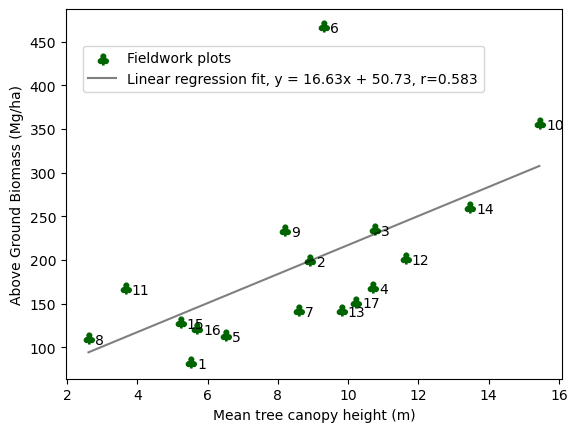

In [ ]:
import matplotlib.pyplot as plt

idx = np.where(good)[0]
plt.scatter(meanCH_tree[good], agbd[good], c="darkgreen", marker=r'$\clubsuit$',s=70)
for i in idx:
    plt.annotate(str(i+1), (meanCH_tree[i], agbd[i]), (meanCH_tree[i]+0.2, agbd[i]-7))  #changed annotation to i+1 to match to fieldwork plot numbering

xs = np.linspace(np.nanmin(meanCH_tree), np.nanmax(meanCH_tree), 50)
plt.plot(xs, res.slope * xs + res.intercept, color= 'black', alpha =0.5)
plt.xlabel('Mean tree canopy height (m)')
plt.legend(["Fieldwork plots", 'Linear regression fit, y = 16.63x + 50.73, r=0.583'], loc='upper left',  bbox_to_anchor=(0.02, 0.92))
plt.ylabel('Above Ground Biomass (Mg/ha)')
plt.show()



In [ ]:
for i in idx:
    print(f'plot {i+1}: meanCH = {meanCH_tree[i]:.2f}, AGBD = {agbd[i]:.2f}')


plot 1: meanCH = 5.51, AGBD = 83.13
plot 2: meanCH = 8.90, AGBD = 200.08
plot 3: meanCH = 10.72, AGBD = 235.88
plot 4: meanCH = 10.68, AGBD = 168.64
plot 5: meanCH = 6.49, AGBD = 114.42
plot 6: meanCH = 9.28, AGBD = 468.00
plot 7: meanCH = 8.58, AGBD = 142.06
plot 8: meanCH = 2.61, AGBD = 110.30
plot 9: meanCH = 8.19, AGBD = 234.61
plot 10: meanCH = 15.45, AGBD = 357.25
plot 11: meanCH = 3.65, AGBD = 167.56
plot 12: meanCH = 11.61, AGBD = 201.80
plot 13: meanCH = 9.79, AGBD = 142.54
plot 14: meanCH = 13.46, AGBD = 260.58
plot 15: meanCH = 5.21, AGBD = 129.35
plot 16: meanCH = 5.68, AGBD = 121.95
plot 17: meanCH = 10.20, AGBD = 152.34


##### Leave-one-out cross-validation (LOOCV) accuracy test

In [ ]:
idx = np.where(good)[0]
pred = np.zeros(len(idx))
for j, i in enumerate(idx):
    keep = idx[idx != i]
    r = linregress(meanCH_tree[keep], agbd[keep])
    pred[j] = r.slope * meanCH_tree[i] + r.intercept

err = pred - agbd[idx]
for j, i in enumerate(idx):
    print(f'plot {i}: observed {agbd[i]:.0f} | predicted {pred[j]:.0f} | error {err[j]:+.0f}')
print('LOO RMSE:', round(float(np.sqrt(np.mean(err**2))), 1), 'Mg/ha | bias:', round(float(err.mean()), 1))

plot 0: observed 83 | predicted 150 | error +67
plot 1: observed 200 | predicted 199 | error -1
plot 2: observed 236 | predicted 228 | error -7
plot 3: observed 169 | predicted 234 | error +65
plot 4: observed 114 | predicted 163 | error +48
plot 5: observed 468 | predicted 188 | error -280
plot 6: observed 142 | predicted 197 | error +55
plot 7: observed 110 | predicted 89 | error -22
plot 8: observed 235 | predicted 184 | error -51
plot 9: observed 357 | predicted 285 | error -72
plot 10: observed 168 | predicted 98 | error -69
plot 11: observed 202 | predicted 249 | error +47
plot 12: observed 143 | predicted 219 | error +76
plot 13: observed 261 | predicted 278 | error +17
plot 14: observed 129 | predicted 138 | error +9
plot 15: observed 122 | predicted 148 | error +26
plot 16: observed 152 | predicted 226 | error +73
LOO RMSE: 84.0 Mg/ha | bias: -1.1


In [ ]:
import numpy as np
from scipy.stats import linregress

idx = np.where(good)[0]

pred_loo = np.zeros(len(idx))   # prediction for the left-out plot
rmse_loo = np.zeros(len(idx))   # RMSE on the training set of each LOO fit
r2_loo   = np.zeros(len(idx))   # R^2 on the training set of each LOO fit

for j, i in enumerate(idx):
    # indices used to fit the model (all except i)
    keep = idx[idx != i]

    # fit model on training subset
    r = linregress(meanCH_tree[keep], agbd[keep])

    # prediction for the left-out observation
    pred_loo[j] = r.slope * meanCH_tree[i] + r.intercept

    # predictions on the training data (for per-LOO RMSE and R^2)
    y_train      = agbd[keep]
    yhat_train   = r.slope * meanCH_tree[keep] + r.intercept
    resid_train  = yhat_train - y_train

    # RMSE for this particular LOO fit (on training data)
    rmse_loo[j] = np.sqrt(np.mean(resid_train**2))

    # R^2 for this particular LOO fit (on training data)
    ss_res = np.sum((y_train - yhat_train)**2)
    ss_tot = np.sum((y_train - y_train.mean())**2)
    r2_loo[j] = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

# errors for the left-out predictions
err = pred_loo - agbd[idx]

# print per-plot results
for j, i in enumerate(idx):
    print(
        f'plot {i}: '
        f'observed {agbd[i]:.0f} | '
        f'predicted {pred_loo[j]:.0f} | '
        f'error {err[j]:+.0f} | '
        f'LOO train RMSE {rmse_loo[j]:.1f} | '
        f'LOO train R^2 {r2_loo[j]:.3f}'
    )

# overall LOO prediction performance
loo_rmse = float(np.sqrt(np.mean(err**2)))
loo_bias = float(err.mean())
print('Overall LOO RMSE:', round(loo_rmse, 1), 'Mg/ha | bias:', round(loo_bias, 1))

# summary of the distribution of per-LOO RMSE and R^2
print('Per-LOO RMSE: mean', rmse_loo.mean(), 'min', rmse_loo.min(), 'max', rmse_loo.max())
print('Per-LOO R^2:  mean', r2_loo.mean(), 'min', r2_loo.min(), 'max', r2_loo.max())


plot 0: observed 83 | predicted 150 | error +67 | LOO train RMSE 78.0 | LOO train R^2 0.306
plot 1: observed 200 | predicted 199 | error -1 | LOO train RMSE 79.5 | LOO train R^2 0.338
plot 2: observed 236 | predicted 228 | error -7 | LOO train RMSE 79.5 | LOO train R^2 0.331
plot 3: observed 169 | predicted 234 | error +65 | LOO train RMSE 78.0 | LOO train R^2 0.361
plot 4: observed 114 | predicted 163 | error +48 | LOO train RMSE 78.7 | LOO train R^2 0.323
plot 5: observed 468 | predicted 188 | error -280 | LOO train RMSE 41.5 | LOO train R^2 0.622
plot 6: observed 142 | predicted 197 | error +55 | LOO train RMSE 78.4 | LOO train R^2 0.345
plot 7: observed 110 | predicted 89 | error -22 | LOO train RMSE 79.4 | LOO train R^2 0.308
plot 8: observed 235 | predicted 184 | error -51 | LOO train RMSE 78.6 | LOO train R^2 0.347
plot 9: observed 357 | predicted 285 | error -72 | LOO train RMSE 78.1 | LOO train R^2 0.216
plot 10: observed 168 | predicted 98 | error -69 | LOO train RMSE 78.0 | 

Sensitivity check - leaving out plot 5 (6 in raw data)

In [ ]:
keep = good.copy()
keep[5] = False

res_no5 = linregress(meanCH_tree[keep], agbd[keep])
print(f'Without plot 5: AGBD = {res_no5.slope:.2f} * MCH_tree + {res_no5.intercept:.2f}')
print(f'R2 = {res_no5.rvalue**2:.2f} | p = {res_no5.pvalue:.3g} | n = {keep.sum()}')

idx2 = np.where(keep)[0]
pred2 = []
for i in idx2:
    k = idx2[idx2 != i]
    r = linregress(meanCH_tree[k], agbd[k])
    pred2.append(r.slope * meanCH_tree[i] + r.intercept)
err2 = np.array(pred2) - agbd[idx2]
print('LOO RMSE without plot 5:', round(float(np.sqrt(np.mean(err2**2))), 1), 'Mg/ha')

Without plot 5: AGBD = 15.59 * MCH_tree + 43.15
R2 = 0.62 | p = 0.000281 | n = 16
LOO RMSE without plot 5: 49.8 Mg/ha


In [ ]:
import numpy as np

agbd[agbd < 0.0] = np.nan

print(agbd)


[ 83.1341462 200.081791  235.8795628 168.6369671 114.4238185 468.0025976
 142.0598674 110.2960442 234.6105473 357.2461161 167.5570338 201.797053
 142.540555  260.581227  129.3485631 121.9499023 152.3356016]


In [ ]:
import numpy as np

usableBiomass = agbd[np.isnan(agbd) == False]

print("Usable Biomass:", usableBiomass)

Usable Biomass: [ 83.1341462 200.081791  235.8795628 168.6369671 114.4238185 468.0025976
 142.0598674 110.2960442 234.6105473 357.2461161 167.5570338 201.797053
 142.540555  260.581227  129.3485631 121.9499023 152.3356016]


In [ ]:
usableCH = meanCH[np.isnan(meanCH) == False]

#### Calculate the 2D biomass array

In [6]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.transform import Affine

src_path = '/home/s2955015/scratch/LiDAR/CHM_clean/CHMclippedtoOS_clean.tif'
out_path = '/home/s2955015/scratch/LiDAR/CHM_clean/CHM_meantree_20m.tif'

CELL_M = 20     # cell size (m)
MIN_H = 2.0     # same rule as meanCH_tree: pixels below this count as 0 m

with rasterio.open(src_path) as src:
    f = int(round(CELL_M / src.res[0]))        # pixels per cell side (40 for 0.5 m)
    H, W = src.height // f, src.width // f
    print('pixels per cell side:', f, '| output grid:', H, 'x', W)
    if src.height % f or src.width % f:
        print('NOTE: edge pixels that do not fill a whole cell are dropped')

    mean = np.full((H, W), -9999.0, dtype='float32')   # mean tree CHM per cell
    vfrac = np.zeros((H, W), dtype='float32')          # fraction of the cell with valid data

    for r in range(H):
        a = src.read(1, window=Window(0, r * f, W * f, f), masked=True)
        nod = np.ma.getmaskarray(a)                    # True where nodata
        d = np.where(nod, 0, a.data)
        d = np.where(d >= MIN_H, d, 0).reshape(f, W, f)    # zero everything under 2 m
        valid = (~nod).reshape(f, W, f)

        n = valid.sum(axis=(0, 2))                     # valid pixels per cell
        ok = n > 0
        mean[r, ok] = d.sum(axis=(0, 2))[ok] / n[ok]   # mean over valid pixels only
        vfrac[r] = n / (f * f)

        if r % 100 == 0:
            print('row', r, 'of', H)

    profile = dict(driver='GTiff', dtype='float32', count=2, width=W, height=H,
                   crs=src.crs, transform=src.transform * Affine.scale(f, f),
                   nodata=-9999.0, compress='lzw')

with rasterio.open(out_path, 'w', **profile) as dst:
    dst.write(mean, 1)       # band 1: mean tree CHM (m), 2 m rule applied
    dst.write(vfrac, 2)      # band 2: fraction of the cell with valid data
    dst.set_band_description(1, 'mean_tree_CHM_m')
    dst.set_band_description(2, 'valid_fraction')

print('Written to', out_path)
print('cells with data:', int((vfrac > 0).sum()), '| cells >= 70% valid:', int((vfrac >= 0.7).sum()))

pixels per cell side: 40 | output grid: 1036 x 1139
NOTE: edge pixels that do not fill a whole cell are dropped
row 0 of 1036
row 100 of 1036
row 200 of 1036
row 300 of 1036
row 400 of 1036
row 500 of 1036
row 600 of 1036
row 700 of 1036
row 800 of 1036
row 900 of 1036
row 1000 of 1036
Written to /home/s2955015/scratch/LiDAR/CHM_clean/CHM_meantree_20m.tif
cells with data: 79328 | cells >= 70% valid: 61226


In [11]:
with rasterio.open(out_path) as s:
    vals = np.array(list(s.sample(zip(x, y))))
cell_mean, cell_vfrac = vals[:, 0], vals[:, 1]

for i in range(len(x)):
    print(f'plot {i+1}: circle {meanCH_tree[i]:.2f} m | 20 m cell {cell_mean[i]:.2f} m | cell valid {cell_vfrac[i]:.0%}')
print('correlation:', np.round(np.corrcoef(meanCH_tree, cell_mean)[0, 1], 2))

plot 1: circle 5.51 m | 20 m cell 5.12 m | cell valid 100%
plot 2: circle 8.90 m | 20 m cell 9.56 m | cell valid 100%
plot 3: circle 10.72 m | 20 m cell 10.49 m | cell valid 100%
plot 4: circle 10.68 m | 20 m cell 10.81 m | cell valid 100%
plot 5: circle 6.49 m | 20 m cell 5.04 m | cell valid 100%
plot 6: circle 9.28 m | 20 m cell 9.26 m | cell valid 100%
plot 7: circle 8.58 m | 20 m cell 16.63 m | cell valid 100%
plot 8: circle 2.61 m | 20 m cell 3.17 m | cell valid 98%
plot 9: circle 8.19 m | 20 m cell 6.34 m | cell valid 74%
plot 10: circle 15.45 m | 20 m cell 15.62 m | cell valid 100%
plot 11: circle 3.65 m | 20 m cell 4.77 m | cell valid 100%
plot 12: circle 11.61 m | 20 m cell 12.59 m | cell valid 100%
plot 13: circle 9.79 m | 20 m cell 10.69 m | cell valid 100%
plot 14: circle 13.46 m | 20 m cell 12.04 m | cell valid 88%
plot 15: circle 5.21 m | 20 m cell 5.66 m | cell valid 100%
plot 16: circle 5.68 m | 20 m cell 4.56 m | cell valid 100%
plot 17: circle 10.20 m | 20 m cell 10.4

#### Creating the carbon map

First make the biomass array

In [16]:
import numpy as np
import rasterio

in_path  = '/home/s2955015/scratch/LiDAR/CHM_clean/CHM_meantree_20m.tif'
out_path = '/home/s2955015/scratch/LiDAR/CHM_clean/AGBD_20m.tif'

m, c = 16.63, 50.73     # fit on all 17 plots
MIN_VALID = 0.7         # minimum fraction of valid pixels in a cell
MIN_MCH = 2.0           # below this mean tree height, biomass = 0

with rasterio.open(in_path) as src:
    mch = src.read(1)
    vf = src.read(2)
    profile = src.profile

agbd_map = np.full(mch.shape, -9999.0, dtype='float32')

keep = (mch != -9999) & (vf >= MIN_VALID)
agbd_map[keep] = m * mch[keep] + c

low = keep & (mch < MIN_MCH)
agbd_map[low] = 0.0

profile.update(count=1, dtype='float32', nodata=-9999.0)
with rasterio.open(out_path, 'w', **profile) as dst:
    dst.write(agbd_map, 1)

has_data = (mch != -9999)
print('cells with any data:       ', int(has_data.sum()))
print('dropped (< 70% valid):     ', int((has_data & (vf < MIN_VALID)).sum()))
print('set to zero (low height):  ', int(low.sum()))
print('cells with biomass > 0:    ', int((agbd_map > 0).sum()))
v = agbd_map[agbd_map > 0]
print('biomass in those cells (Mg/ha): mean', round(float(v.mean()), 1),
      '| 99th percentile', round(float(np.percentile(v, 99)), 1),
      '| max', round(float(v.max()), 1))
print('Written to', out_path)

cells with any data:        79328
dropped (< 70% valid):      18102
set to zero (low height):   38405
cells with biomass > 0:     22821
biomass in those cells (Mg/ha): mean 193.2 | 99th percentile 411.6 | max 569.3
Written to /home/s2955015/scratch/LiDAR/CHM_clean/AGBD_20m.tif


Now the carbon array raster. 

In [23]:
import numpy as np
import rasterio

in_path   = '/home/s2955015/scratch/LiDAR/CHM_clean/CHM_meantree_20m.tif'
agb_path  = '/home/s2955015/scratch/LiDAR/CHM_clean/AGBD_20m_2m.tif'
agc_path  = '/home/s2955015/scratch/LiDAR/CHM_clean/AGC_20m_2m.tif'

m, c = 16.63, 50.73     # fit on all 17 plots
MIN_VALID = 0.7
MIN_MCH = 2.0           # same rule as the plot calculation
CARBON = 0.47

with rasterio.open(in_path) as src:
    mch, vf = src.read(1), src.read(2)
    profile = src.profile

keep = (mch != -9999) & (vf >= MIN_VALID)
agb = np.full(mch.shape, -9999.0, dtype='float32')
agb[keep] = np.where(mch[keep] >= MIN_MCH, m * mch[keep] + c, 0.0)

agc = np.where(agb != -9999.0, agb * CARBON, -9999.0).astype('float32')

profile.update(count=1, dtype='float32', nodata=-9999.0)
for path, arr in [(agb_path, agb), (agc_path, agc)]:
    with rasterio.open(path, 'w', **profile) as dst:
        dst.write(arr, 1)

cell_ha = 20 * 20 / 10000
ok = agb != -9999.0
print('total AGB:', round(float(agb[ok].sum() * cell_ha / 1000)), 'thousand Mg')
print('total AGC:', round(float(agc[ok].sum() * cell_ha / 1000)), 'thousand Mg C')
print('mean AGB in tree cells:', round(float(agb[agb > 0].mean())), 'Mg/ha')

total AGB: 176 thousand Mg
total AGC: 83 thousand Mg C
mean AGB in tree cells: 193 Mg/ha


##### Validation tests

Testing cells above calibration range

In [19]:
with rasterio.open('/home/s2955015/scratch/LiDAR/CHM_clean/CHM_meantree_20m.tif') as s:
    mch, vf = s.read(1), s.read(2)

keep = (mch != -9999) & (vf >= 0.7)
cell_ha = 20 * 20 / 10000
m, c = 16.63, 50.73

for t in [0.5, 1.0, 1.5, 2.0, 2.6]:
    tree = keep & (mch >= t)
    b = np.where(tree, m * mch + c, 0)
    print(f'threshold {t} m: {int(tree.sum())} tree cells | total {b.sum() * cell_ha / 1000:.0f} thousand Mg')

above = keep & (mch > 15.5)
b_all = np.where(keep & (mch >= 1.0), m * mch + c, 0)
print('cells above the calibration range (> 15.5 m):', int(above.sum()),
      f'| share of total biomass: {b_all[above].sum() / b_all.sum():.1%}')

threshold 0.5 m: 30887 tree cells | total 199 thousand Mg
threshold 1.0 m: 27181 tree cells | total 189 thousand Mg
threshold 1.5 m: 24729 tree cells | total 182 thousand Mg
threshold 2.0 m: 22821 tree cells | total 176 thousand Mg
threshold 2.6 m: 20913 tree cells | total 170 thousand Mg
cells above the calibration range (> 15.5 m): 2638 | share of total biomass: 19.7%


In [20]:

t = 2.0
tree = keep & (mch >= t)

b_lin = np.where(tree, m * mch + c, 0)                      # straight line, as in the map
b_cap = np.where(tree, m * np.minimum(mch, 15.5) + c, 0)    # flattened at 15.5 m

print(f'linear:  {b_lin.sum() * cell_ha / 1000:.0f} thousand Mg | mean in tree cells {b_lin[tree].mean():.0f} Mg/ha')
print(f'capped:  {b_cap.sum() * cell_ha / 1000:.0f} thousand Mg | mean in tree cells {b_cap[tree].mean():.0f} Mg/ha')

linear:  176 thousand Mg | mean in tree cells 193 Mg/ha
capped:  171 thousand Mg | mean in tree cells 188 Mg/ha


Checking mean heights

In [28]:
print('plots: mean height', round(float(meanCH_tree[good].mean()), 2),
      '| mean AGBD', round(float(agbd[good].mean()), 1))

with rasterio.open('/home/s2955015/scratch/LiDAR/CHM_clean/CHM_meantree_20m.tif') as s:
    mch, vf = s.read(1), s.read(2)
tree = (mch != -9999) & (vf >= 0.7) & (mch >= 2.0)
print('map tree cells: mean height', round(float(mch[tree].mean()), 2),
      '| implied AGBD', round(float(16.63 * mch[tree].mean() + 50.73), 1))

plots: mean height 8.59 | mean AGBD 193.6
map tree cells: mean height 8.56 | implied AGBD 193.2
